# MobileOne — An Improved One Millisecond Mobile Backbone

**Paper:** Vasu, P. K. A., Gabriel, J., Zhu, J., Tuzel, O., & Ranjan, A. (2023). MobileOne: An Improved One millisecond Mobile Backbone. *CVPR 2023*. https://arxiv.org/abs/2206.04040

**Implementation:** `hale_core/nn/vision/cnn/mobile_one.py`

> MobileOne uses *structural re-parameterisation*: train with multiple parallel branches for expressiveness, then fuse all branches into a single conv at inference — achieving both high accuracy and sub-millisecond latency on mobile hardware.

> 📄 **Paper:** Vasu et al. (2023). MobileOne: An Improved One Millisecond Mobile Backbone. CVPR 2023.
> 🔗 **Link:** <https://arxiv.org/abs/2206.04040>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/mobile_one.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> S0["stage 0 /2"]:::stage --> S1["stages 1–4 of MobileOne blocks /4 … /32"]:::stage --> GAP["avg pool"]:::block --> OUT
  subgraph TRAIN["train time: over-parameterised branches"]
    direction LR
    X["x"] --> K1["k × (conv · BN)"]:::block
    X --> SC["1×1 conv · BN (scale)"]:::block
    X --> ID["BN (identity)"]:::block
    K1 & SC & ID --> ADD(("+")) --> ACT["ReLU"]:::block
  end
  subgraph INFER["inference: re-parameterised"]
    direction LR
    Y["x"] --> ONE["single conv (fused weights + bias)"]:::block --> ACT2["ReLU"]:::block
  end
  TRAIN == "reparameterize()" ==> INFER
  S1 -.-> TRAIN
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Overview

```
TRAINING MODE (MobileOneBlock, k branches):

Input x [B, C_in, H, W]
       │
  ┌────┼────────────────────────────────────────────────┐
  │    │  DEPTHWISE STAGE                               │
  │    ├─ 3×3 DW conv + BN  (×k branches)              │
  │    ├─ 1×1 DW conv + BN  (skip-like)                │
  │    └─ BN only           (identity, if same dims)    │
  │    → SUM all branch outputs → ReLU                  │
  └────────────────────────────────────────────────────┘
       │
  ┌────┼────────────────────────────────────────────────┐
  │    │  POINTWISE STAGE                              │
  │    ├─ 1×1 PW conv + BN  (×k branches)              │
  │    └─ BN only           (identity, if same dims)    │
  │    → SUM → ReLU                                     │
  └────────────────────────────────────────────────────┘

INFERENCE MODE (after reparametrize()):

Input x [B, C_in, H, W]
  → reparam_dw (single fused 3×3 DW conv + bias)
  → ReLU
  → reparam_pw (single fused 1×1 PW conv + bias)
  → ReLU
  → Output [B, C_out, H, W]

BN Fusion Formula:
  W_fused = (γ/√(σ²+ε)) · W_conv       scale per output channel
  b_fused = β - γ·μ/√(σ²+ε)           shift per output channel
  Sum over all k branches + pad 1×1→3×3 + add identity branch
```

/var/folders/_q/55b37d8s6sq3xq4j5ll92c400000gn/T/ipykernel_57783/2907325625.py:118: UserWarning: Glyph 10233 (\N{LONG RIGHTWARDS DOUBLE ARROW}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/private/tmp/claude-501/-Users-naveenkumarbasaanitha-Music/039335b9-677c-49c3-bf01-63bdd0baece4/scratchpad/nbenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10233 (\N{LONG RIGHTWARDS DOUBLE ARROW}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)


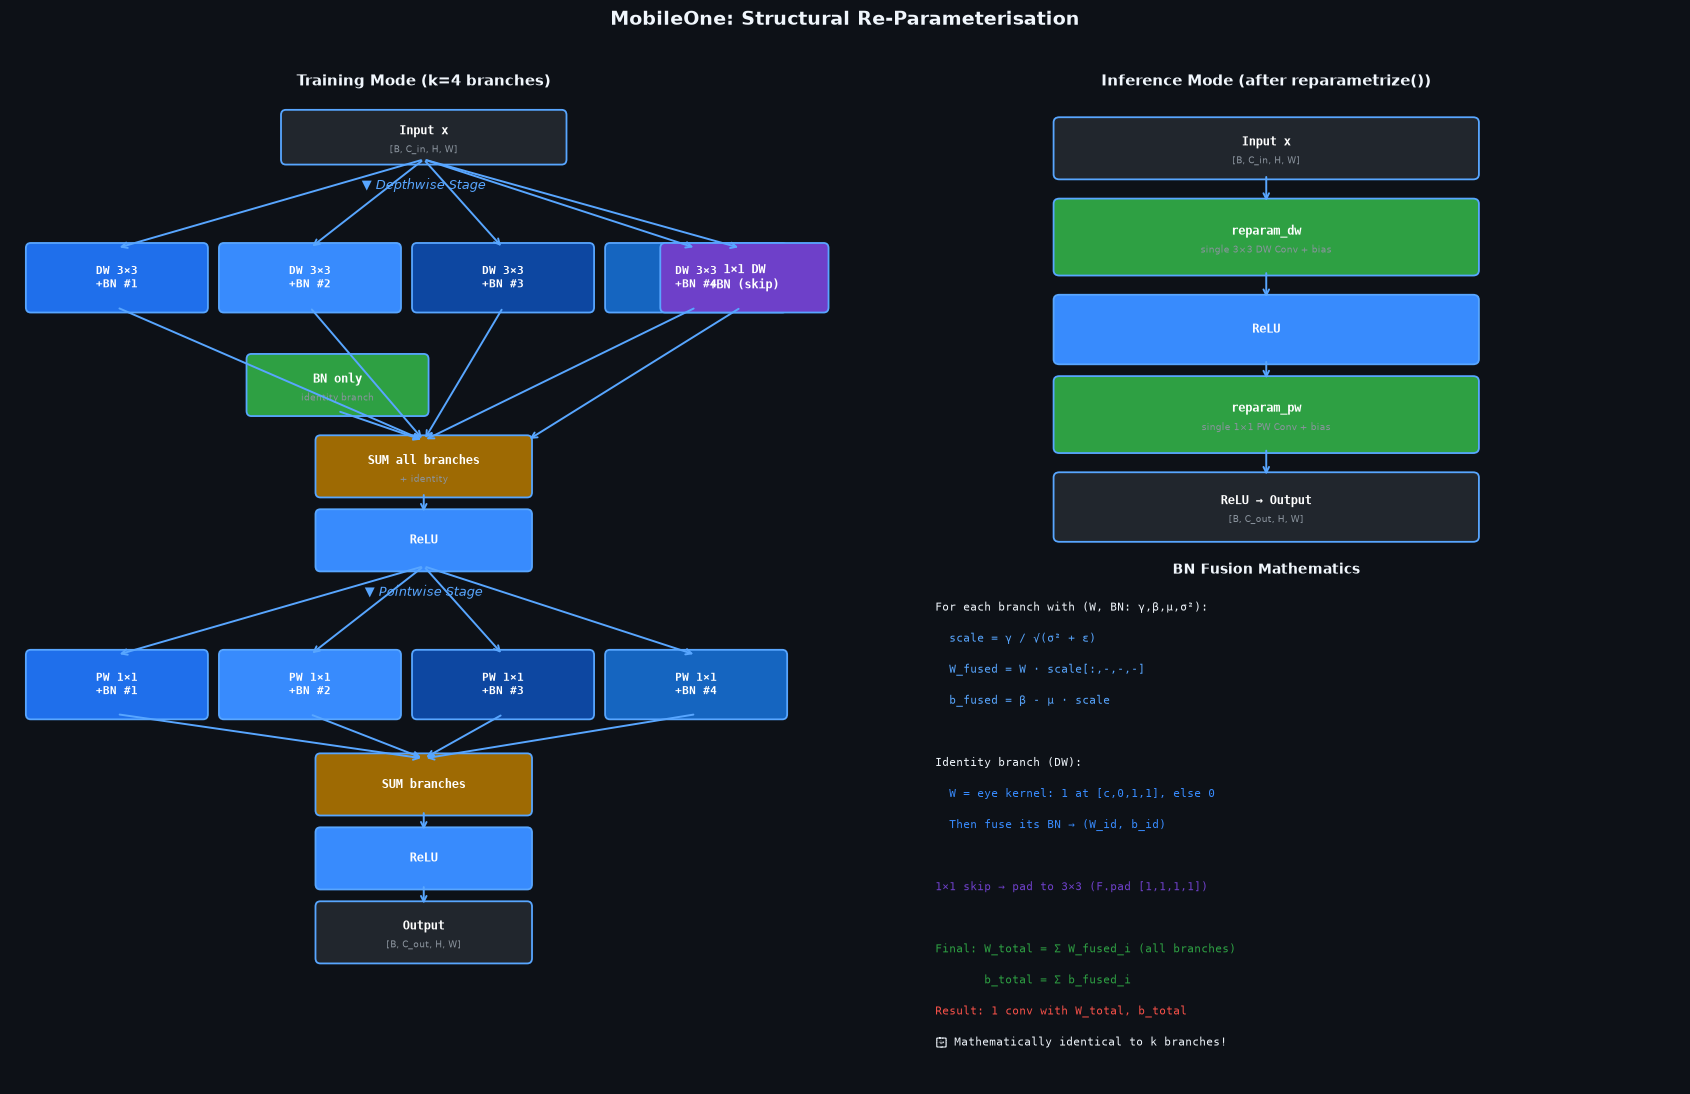

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(17, 11))
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#0d1117')
    ax.axis('off')

def box(ax, x, y, w, h, text, sub='', fc='#1f6feb', fontsize=8.5):
    r = FancyBboxPatch((x,y), w, h, boxstyle='round,pad=0.07',
                        facecolor=fc, edgecolor='#58a6ff', lw=1.3)
    ax.add_patch(r)
    ax.text(x+w/2, y+h/2+(0.08 if sub else 0), text, ha='center', va='center',
            color='white', fontsize=fontsize, fontweight='bold', fontfamily='monospace')
    if sub:
        ax.text(x+w/2, y+h/2-0.17, sub, ha='center', va='center',
                color='#8b949e', fontsize=6.5)

def arr(ax, x1,y1,x2,y2,c='#58a6ff'):
    ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
                arrowprops=dict(arrowstyle='->', color=c, lw=1.4))

# ── LEFT: Training mode multi-branch ──────────────────────────────────────────
ax = axes[0]
ax.set_xlim(0, 12)
ax.set_ylim(0, 14)
ax.text(6, 13.5, 'Training Mode (k=4 branches)', ha='center',
        color='#f0f6fc', fontsize=11, fontweight='bold')

box(ax, 4, 12.5, 4, 0.6, 'Input x', '[B, C_in, H, W]', fc='#21262d')
ax.text(6, 12.1, '▼ Depthwise Stage', ha='center', color='#58a6ff', fontsize=9, fontstyle='italic')

# 4 branches depthwise
branch_colors = ['#1f6feb','#388bfd','#0d47a1','#1565c0']
for i in range(4):
    bx = 0.3 + i*2.8
    box(ax, bx, 10.5, 2.5, 0.8, f'DW 3×3\n+BN #{i+1}', '', fc=branch_colors[i], fontsize=8)
    arr(ax, 6, 12.5, bx+1.25, 11.3)

# 1x1 skip
box(ax, 9.5, 10.5, 2.3, 0.8, '1×1 DW\n+BN (skip)', '', fc='#6e40c9')
arr(ax, 6, 12.5, 10.6, 11.3)

# identity BN
box(ax, 3.5, 9.1, 2.5, 0.7, 'BN only', 'identity branch', fc='#2ea043')

# Σ
box(ax, 4.5, 8.0, 3, 0.7, 'SUM all branches', '+ identity', fc='#9e6a03')
for i in range(4):
    arr(ax, 0.3+i*2.8+1.25, 10.5, 6, 8.7)
arr(ax, 10.6, 10.5, 7.5, 8.7)
arr(ax, 4.75, 9.1, 6, 8.7)

box(ax, 4.5, 7.0, 3, 0.7, 'ReLU', '', fc='#388bfd')
arr(ax, 6, 8.0, 6, 7.7)

ax.text(6, 6.6, '▼ Pointwise Stage', ha='center', color='#58a6ff', fontsize=9, fontstyle='italic')

for i in range(4):
    bx = 0.3 + i*2.8
    box(ax, bx, 5.0, 2.5, 0.8, f'PW 1×1\n+BN #{i+1}', '', fc=branch_colors[i], fontsize=8)
    arr(ax, 6, 7.0, bx+1.25, 5.8)

box(ax, 4.5, 3.7, 3, 0.7, 'SUM branches', '', fc='#9e6a03')
for i in range(4):
    arr(ax, 0.3+i*2.8+1.25, 5.0, 6, 4.4)

box(ax, 4.5, 2.7, 3, 0.7, 'ReLU', '', fc='#388bfd')
arr(ax, 6, 3.7, 6, 3.4)
box(ax, 4.5, 1.7, 3, 0.7, 'Output', '[B, C_out, H, W]', fc='#21262d')
arr(ax, 6, 2.7, 6, 2.4)

# ── RIGHT: Inference mode + reparameterisation math ──────────────────────────
ax = axes[1]
ax.set_xlim(0, 10)
ax.set_ylim(0, 14)
ax.text(5, 13.5, 'Inference Mode (after reparametrize())', ha='center',
        color='#f0f6fc', fontsize=11, fontweight='bold')

box(ax, 2.5, 12.3, 5, 0.7, 'Input x', '[B, C_in, H, W]', fc='#21262d')
box(ax, 2.5, 11.0, 5, 0.9, 'reparam_dw', 'single 3×3 DW Conv + bias', fc='#2ea043')
arr(ax, 5, 12.3, 5, 11.9)
box(ax, 2.5, 9.8, 5, 0.8, 'ReLU', '', fc='#388bfd')
arr(ax, 5, 11.0, 5, 10.6)
box(ax, 2.5, 8.6, 5, 0.9, 'reparam_pw', 'single 1×1 PW Conv + bias', fc='#2ea043')
arr(ax, 5, 9.8, 5, 9.5)
box(ax, 2.5, 7.4, 5, 0.8, 'ReLU → Output', '[B, C_out, H, W]', fc='#21262d')
arr(ax, 5, 8.6, 5, 8.2)

# BN fusion math
ax.text(5, 6.9, 'BN Fusion Mathematics', ha='center', color='#f0f6fc',
        fontsize=10, fontweight='bold')

lines = [
    ('For each branch with (W, BN: γ,β,μ,σ²):', '#f0f6fc'),
    ('  scale = γ / √(σ² + ε)', '#58a6ff'),
    ('  W_fused = W · scale[:,-,-,-]', '#58a6ff'),
    ('  b_fused = β - μ · scale', '#58a6ff'),
    ('', '#8b949e'),
    ('Identity branch (DW):', '#f0f6fc'),
    ('  W = eye kernel: 1 at [c,0,1,1], else 0', '#388bfd'),
    ('  Then fuse its BN → (W_id, b_id)', '#388bfd'),
    ('', '#8b949e'),
    ('1×1 skip → pad to 3×3 (F.pad [1,1,1,1])', '#6e40c9'),
    ('', '#8b949e'),
    ('Final: W_total = Σ W_fused_i (all branches)', '#2ea043'),
    ('       b_total = Σ b_fused_i', '#2ea043'),
    ('Result: 1 conv with W_total, b_total', '#f85149'),
    ('⟹ Mathematically identical to k branches!', '#f0f6fc'),
]
for i, (line, color) in enumerate(lines):
    ax.text(1.0, 6.4 - i*0.42, line, color=color, fontsize=7.8, fontfamily='monospace')

plt.suptitle('MobileOne: Structural Re-Parameterisation', fontsize=14,
             color='#f0f6fc', fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

## 3. Key ideas

## Key Innovations

### 1. The Mobile Latency Problem
Mobile models are bottlenecked not just by FLOPs, but by **memory access costs** and **activation functions** (which require reading/writing entire feature maps). Prior mobile architectures (MobileNetV3, EfficientNet-Lite) suffered from:
- Many activation layers → high memory bandwidth
- Batch Norm at train time adds inference overhead if not fused
- Multi-branch designs are needed during training but expensive at inference

### 2. Structural Re-Parameterisation (RepVGG, ECCV 2022)
The key insight: **a sum of linear operations on the same input is another linear operation**. Since `BN(Conv(x)) = W'x + b'` (a linear function of x), and the sum of linear functions is linear, all branches can be fused into one.

MobileOne extends RepVGG to the depthwise-pointwise factorisation:
- **Depthwise stage**: k branches of 3×3 DW + BN, 1 branch of 1×1 DW + BN, 1 identity BN
- **Pointwise stage**: k branches of 1×1 PW + BN, 1 identity BN

### 3. BN Fusion Derivation
For a conv with weight W and BN (γ, β, μ, σ²):
```
BN(Conv(x)) = γ·(W⊛x − μ)/√(σ²+ε) + β
            = (γ/√(σ²+ε))·W ⊛ x + (β − γμ/√(σ²+ε))
            = W_fused ⊛ x + b_fused
```
For k branches: sum = `(Σ W_fused_i) ⊛ x + Σ b_fused_i`

For the 1×1 skip branch: pad the 1×1 weight to 3×3 by adding zeros around the centre — then fuse normally.

For the identity BN: the equivalent 3×3 DW conv weight is a delta kernel (1 at centre, 0 elsewhere).

### 4. k Branches During Training
More branches → more capacity → better accuracy at equal inference cost. k=4 is used in practice. After training, call `reparametrize()` to fold all branches. The model then runs as a simple sequence of DW+PW convolutions.

### 5. Hardware Characteristics
MobileOne was specifically designed for Apple Neural Engine (ANE) and CoreML. The single-branch inference path (no skip connections, no branching) maximises hardware parallelism on accelerators that are optimised for linear pipelines.

## Component Walkthrough

### `_fuse_bn` helper (lines 62–87 in `mobile_one.py`)
```python
def _fuse_bn(conv, bn):
    w    = conv.weight                        # [C_out, C_in/G, kH, kW]
    scale = bn.weight / (bn.running_var + bn.eps).sqrt()  # γ/σ per channel
    w_fused = w * scale.view(-1, 1, 1, 1)    # scale each output channel's kernel
    b_fused = bn.bias - bn.running_mean * scale  # β - μγ/σ
    return w_fused, b_fused
```

### `MobileOneBlock.reparametrize` (lines 205–273 in `mobile_one.py`)
```python
def reparametrize(self):
    # Accumulate all depthwise branches
    dw_w = torch.zeros_like(self.dw_branches[0][0].weight)  # [C, 1, 3, 3]
    dw_b = torch.zeros(self.in_channels)
    for branch in self.dw_branches:
        w, b = _fuse_bn(branch[0], branch[1])
        dw_w += w;  dw_b += b
    if self.dw_skip_1x1:
        w, b = _fuse_bn(self.dw_skip_1x1[0], self.dw_skip_1x1[1])
        dw_w += F.pad(w, [1,1,1,1])  # pad 1×1 → 3×3
        dw_b += b
    if self.dw_bn:
        eye_w = _identity_dw_kernel(self.in_channels)  # delta kernel
        scale = self.dw_bn.weight / (self.dw_bn.running_var + self.dw_bn.eps).sqrt()
        dw_w += eye_w * scale[:, None, None, None]
        dw_b += self.dw_bn.bias - self.dw_bn.running_mean * scale
    self.reparam_dw = nn.Conv2d(..., bias=True)
    self.reparam_dw.weight.data = dw_w
    self.reparam_dw.bias.data   = dw_b
    # ... same for pointwise ...
    del self.dw_branches, self.dw_skip_1x1, self.dw_bn  # free memory
    self._is_reparam = True
```

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/mobile_one.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/mobile_one.py</code></summary>

```text
MobileOne — Re-Parameterisable Efficient Backbone (Vasu et al. 2022, Apple Research)
======================================================================================

Reference: "MobileOne: An Improved One millisecond Mobile Backbone"
           https://arxiv.org/abs/2206.04040

Key Idea: Structural Re-Parameterisation
-----------------------------------------
At TRAINING time, each MobileOne block uses MULTIPLE parallel branches:
  - k branches of depthwise 3×3 conv (each with BN)
  - k branches of 1×1 pointwise conv (each with BN)
  - 1 identity branch (BN only, if in_channels == out_channels and stride == 1)

At INFERENCE time, all branches are FUSED into a SINGLE 3×3 conv + bias,
achieving the same output as all branches combined — but with zero overhead.

This gives the expressiveness of multi-branch training with the efficiency
of single-conv inference.

Reparameterisation formula:
  For each branch (weight W_i, BN: γ, β, μ, σ²), the equivalent conv is:
    W_eq = γ/σ · W_i
    b_eq = β - γ·μ/σ
  All branches are summed: W = Σ W_eq_i, b = Σ b_eq_i

  For the identity branch: W is a 1-in-1-out identity kernel (eye for depthwise,
  pointwise identity), then merged as above.

Why this works:
  BN(Conv(x)) = γ/σ · Conv(x) + (β - γμ/σ)
  Sum of linear ops (BN∘Conv) with same input = single linear op.
  So the entire k-branch structure can be collapsed to one conv.

Variants (s0..s4)
-----------------
  s0: width_multiplier=[0.75, 1.0, 1.0, 2.0], k=4  — smallest, fast on edge
  s1: width_multiplier=[1.5,  1.5, 2.0, 2.5], k=4  — balanced
  s2: width_multiplier=[1.5,  2.0, 2.5, 4.0], k=4  — higher accuracy
  s3: width_multiplier=[2.0,  2.5, 3.0, 4.0], k=4  — large
  s4: width_multiplier=[3.0,  3.5, 3.5, 4.0], k=4  — largest

After reparametrize(), model is in inference mode (single conv per block).
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/mobile_one.py`, definition by definition

In [5]:
def _fuse_bn(conv: nn.Conv2d, bn: nn.BatchNorm2d) -> tuple[torch.Tensor, torch.Tensor]:
    """Merge Conv + BN into a single conv weight + bias tensor.

    Formula:
        W_fused = (γ / sqrt(σ² + ε)) * W_conv
        b_fused = β - γ * μ / sqrt(σ² + ε)

    Args:
        conv: Conv2d (may have bias=False).
        bn:   BatchNorm2d paired with that conv.

    Returns:
        (weight, bias) both as Tensor.
    """
    w    = conv.weight                                     # [C_out, C_in/G, kH, kW]
    mean = bn.running_mean                                 # [C_out]
    var  = bn.running_var                                  # [C_out]
    beta = bn.bias                                         # [C_out]
    gamma = bn.weight                                      # [C_out]
    eps  = bn.eps

    scale = gamma / (var + eps).sqrt()                     # [C_out]
    # reshape scale for broadcasting over spatial dims
    w_fused = w * scale.view(-1, 1, 1, 1)
    b_fused = beta - mean * scale
    return w_fused, b_fused

**`_ConvBN`** - Conv2d → BatchNorm2d (no activation).

In [6]:
class _ConvBN(nn.Sequential):
    """Conv2d → BatchNorm2d (no activation)."""

    def __init__(
        self,
        in_channels:  int,
        out_channels: int,
        kernel_size:  int,
        stride:       int  = 1,
        groups:       int  = 1,
    ) -> None:
        pad = kernel_size // 2
        super().__init__(
            nn.Conv2d(
                in_channels, out_channels, kernel_size,
                stride=stride, padding=pad, groups=groups, bias=False,
            ),
            nn.BatchNorm2d(out_channels),
        )

**`MobileOneBlock`** - A single MobileOne block with structural re-parameterisation.

In [7]:
class MobileOneBlock(nn.Module):
    """A single MobileOne block with structural re-parameterisation.

    In TRAINING mode: uses k parallel branches per conv.
    In INFERENCE mode (after reparametrize()): single fused conv.

    Architecture:
        input
          ↓ Depthwise (groups=in_channels) with k 3×3 branches
          ↓ + identity branch (if stride=1, same C)
        intermediate
          ↓ Pointwise (1×1) with k branches
        output
        (activation applied after both stages by the caller)

    Args:
        in_channels:  Input channel count.
        out_channels: Output channel count.
        stride:       Spatial stride (1 for same-size, 2 for downsampling).
        num_blocks:   k — number of parallel conv branches per stage.
                      k=1 gives the inference model; k>1 for rich training.
        use_act:      Whether to apply ReLU after this block.
    """

    def __init__(
        self,
        in_channels:  int,
        out_channels: int,
        stride:       int  = 1,
        num_blocks:   int  = 1,
        use_act:      bool = True,
    ) -> None:
        super().__init__()
        self.in_channels  = in_channels
        self.out_channels = out_channels
        self.stride       = stride
        self.num_blocks   = num_blocks
        self.use_act      = use_act
        self._is_reparam  = False  # True after reparametrize()

        # ── Depthwise convolution branches ───────────────────────────────────
        self.dw_branches: nn.ModuleList = nn.ModuleList([
            _ConvBN(in_channels, in_channels, kernel_size=3, stride=stride, groups=in_channels)
            for _ in range(num_blocks)
        ])
        # 1×1 branch in depthwise (acts as identity-like for same-size kernels)
        self.dw_skip_1x1: Optional[_ConvBN] = None
        if in_channels == out_channels:
            self.dw_skip_1x1 = _ConvBN(
                in_channels, in_channels, kernel_size=1, stride=stride, groups=in_channels
            )
        # Identity branch for depthwise (only if stride=1 and same channels)
        self.dw_bn: Optional[nn.BatchNorm2d] = None
        if stride == 1 and in_channels == out_channels:
            self.dw_bn = nn.BatchNorm2d(in_channels)

        # ── Pointwise convolution branches ───────────────────────────────────
        self.pw_branches: nn.ModuleList = nn.ModuleList([
            _ConvBN(in_channels, out_channels, kernel_size=1)
            for _ in range(num_blocks)
        ])
        self.pw_bn: Optional[nn.BatchNorm2d] = None
        if in_channels == out_channels:
            # Identity branch for pointwise
            self.pw_bn = nn.BatchNorm2d(in_channels)

        # ── Activation ───────────────────────────────────────────────────────
        self.act = nn.ReLU() if use_act else nn.Identity()

        # ── Reparam'd single conv (filled by reparametrize()) ─────────────────
        self.reparam_dw: Optional[nn.Conv2d] = None
        self.reparam_pw: Optional[nn.Conv2d] = None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self._is_reparam:
            # Fast inference path: single fused conv
            return self.act(self.reparam_pw(self.act(self.reparam_dw(x))))

        # ── Depthwise stage ───────────────────────────────────────────────────
        dw_out = sum(branch(x) for branch in self.dw_branches)
        if self.dw_skip_1x1 is not None:
            dw_out = dw_out + self.dw_skip_1x1(x)
        if self.dw_bn is not None:
            dw_out = dw_out + self.dw_bn(x)      # identity residual (BN only)
        dw_out = self.act(dw_out)

        # ── Pointwise stage ───────────────────────────────────────────────────
        pw_out = sum(branch(dw_out) for branch in self.pw_branches)
        if self.pw_bn is not None:
            pw_out = pw_out + self.pw_bn(dw_out)  # identity residual
        return self.act(pw_out)

    def reparametrize(self) -> None:
        """Fuse all parallel branches into a single conv+bias each.

        After calling this:
          - All branch parameters are deleted (memory freed).
          - self.reparam_dw / self.reparam_pw hold the fused convs.
          - forward() uses the fast inference path.
        """
        if self._is_reparam:
            return

        # ── Fuse depthwise ────────────────────────────────────────────────────
        dw_w = torch.zeros_like(self.dw_branches[0][0].weight)  # [C, 1, 3, 3] for groups=C
        dw_b = torch.zeros(self.in_channels, device=dw_w.device, dtype=dw_w.dtype)

        for branch in self.dw_branches:
            w, b = _fuse_bn(branch[0], branch[1])
            dw_w = dw_w + w
            dw_b = dw_b + b

        if self.dw_skip_1x1 is not None:
            w, b = _fuse_bn(self.dw_skip_1x1[0], self.dw_skip_1x1[1])
            # Pad 1×1 weight to 3×3 (centre) to match branch kernels
            w_padded = F.pad(w, [1, 1, 1, 1])
            dw_w = dw_w + w_padded
            dw_b = dw_b + b

        if self.dw_bn is not None:
            # Identity branch: weight is an identity 3×3 depthwise kernel
            eye_w = _identity_dw_kernel(self.in_channels, device=dw_w.device, dtype=dw_w.dtype)
            scale = self.dw_bn.weight / (self.dw_bn.running_var + self.dw_bn.eps).sqrt()
            bias  = self.dw_bn.bias - self.dw_bn.running_mean * scale
            dw_w  = dw_w + eye_w * scale.view(-1, 1, 1, 1)
            dw_b  = dw_b + bias

        self.reparam_dw = nn.Conv2d(
            self.in_channels, self.in_channels, kernel_size=3,
            stride=self.stride, padding=1, groups=self.in_channels, bias=True,
        )
        self.reparam_dw.weight.data = dw_w
        self.reparam_dw.bias.data   = dw_b

        # ── Fuse pointwise ────────────────────────────────────────────────────
        pw_w = torch.zeros_like(self.pw_branches[0][0].weight)  # [C_out, C_in, 1, 1]
        pw_b = torch.zeros(self.out_channels, device=pw_w.device, dtype=pw_w.dtype)

        for branch in self.pw_branches:
            w, b = _fuse_bn(branch[0], branch[1])
            pw_w = pw_w + w
            pw_b = pw_b + b

        if self.pw_bn is not None and self.in_channels == self.out_channels:
            # Identity branch: weight is 1×1 identity (eye) for pointwise
            eye_w = _identity_pw_kernel(self.in_channels, device=pw_w.device, dtype=pw_w.dtype)
            scale = self.pw_bn.weight / (self.pw_bn.running_var + self.pw_bn.eps).sqrt()
            bias  = self.pw_bn.bias - self.pw_bn.running_mean * scale
            pw_w  = pw_w + eye_w * scale.view(-1, 1, 1, 1)
            pw_b  = pw_b + bias

        self.reparam_pw = nn.Conv2d(
            self.in_channels, self.out_channels, kernel_size=1, bias=True,
        )
        self.reparam_pw.weight.data = pw_w
        self.reparam_pw.bias.data   = pw_b

        # ── Delete training-time branches (free memory) ───────────────────────
        del self.dw_branches, self.dw_skip_1x1, self.dw_bn
        del self.pw_branches, self.pw_bn
        self._is_reparam = True

In [8]:
def _identity_dw_kernel(channels: int, device, dtype) -> torch.Tensor:
    """Create a 3×3 depthwise identity kernel: 1 at centre, 0 elsewhere."""
    w = torch.zeros(channels, 1, 3, 3, device=device, dtype=dtype)
    w[:, 0, 1, 1] = 1.0
    return w

In [9]:
def _identity_pw_kernel(channels: int, device, dtype) -> torch.Tensor:
    """Create a 1×1 pointwise identity kernel: eye matrix reshaped."""
    w = torch.zeros(channels, channels, 1, 1, device=device, dtype=dtype)
    for i in range(channels):
        w[i, i, 0, 0] = 1.0
    return w

**`MobileOneBackbone`** - MobileOne hierarchical CNN backbone.

In [10]:
class MobileOneBackbone(BaseVisionBackbone):
    """MobileOne hierarchical CNN backbone.

    4 stages with progressively wider channels and stride-2 downsampling.
    Multi-scale feature maps returned for FPN/BEV/detection heads.

    Args:
        width_mult: Per-stage width multipliers over base channels [48, 96, 192, 512].
        num_blocks: k branches per block (1 = reparam-ready; 4 = rich training).
        img_size, in_chans, drop_rate: See BaseVisionBackbone.
    """

    arch_name:    str       = "mobile_one"
    embed_dim:    int       = 512          # overridden per variant
    feature_dims: list[int] = []

    _BASE_CHANNELS = [48, 96, 192, 512]    # stage output channels before width scaling
    _DEPTHS        = [2, 8, 10, 1]         # number of blocks per stage

    def __init__(
        self,
        width_mult:  list[float] = (1.0, 1.0, 1.0, 1.0),
        num_blocks:  int         = 1,
        img_size:    int         = 224,
        in_chans:    int         = 3,
        drop_rate:   float       = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        # Compute actual channel counts
        stage_dims = [
            _make_divisible(c * m, 8)
            for c, m in zip(self._BASE_CHANNELS, width_mult)
        ]
        self.feature_dims = stage_dims
        self.embed_dim    = stage_dims[-1]

        super().__init__(img_size=img_size, in_chans=in_chans,
                         drop_rate=drop_rate, out_indices=out_indices)

        self._num_blocks = num_blocks

        # ── Stem (stride-2 conv + MobileOneBlock) ────────────────────────────
        stem_out = _make_divisible(self._BASE_CHANNELS[0] * width_mult[0] / 2, 8)
        self.stem = nn.Sequential(
            _ConvBN(in_chans, stem_out, kernel_size=3, stride=2),
            nn.ReLU(),
            MobileOneBlock(stem_out, stage_dims[0], stride=2, num_blocks=num_blocks),
        )

        # ── Stages ───────────────────────────────────────────────────────────
        # Stage 0 is produced by stem; stages 1-3 further downsample
        self.stages: nn.ModuleList = nn.ModuleList()
        in_c = stage_dims[0]
        for i, (out_c, n_depth) in enumerate(zip(stage_dims[1:], self._DEPTHS[1:]), start=1):
            blocks: list[nn.Module] = []
            # First block: stride 2 to halve resolution
            blocks.append(MobileOneBlock(in_c, out_c, stride=2, num_blocks=num_blocks))
            # Remaining blocks: same resolution
            for _ in range(n_depth - 1):
                blocks.append(MobileOneBlock(out_c, out_c, stride=1, num_blocks=num_blocks))
            self.stages.append(nn.Sequential(*blocks))
            in_c = out_c

        # ── Global pooling for classification/embedding ───────────────────────
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head_drop = nn.Dropout(drop_rate)

        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        # Stage 0 output from stem
        x = self.stem(x)
        all_features: list[torch.Tensor] = [x]

        for stage in self.stages:
            x = stage(x)
            all_features.append(x)

        # Select requested stages
        indices = self.out_indices if self.out_indices is not None else list(range(4))
        feature_maps = [all_features[i] for i in indices if i < len(all_features)]

        # Global pooled embedding
        pooled = self.pool(all_features[-1]).flatten(1)
        pooled = self.head_drop(pooled)

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=feature_maps,
        )

    def reparametrize(self) -> None:
        """Fuse all multi-branch blocks for inference (run once before deployment)."""
        for m in self.modules():
            if isinstance(m, MobileOneBlock):
                m.reparametrize()

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem and the first `stage` stages (0-indexed)."""
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i, s in enumerate(self.stages):
            if i < stage:
                for p in s.parameters():
                    p.requires_grad_(False)

In [11]:
def _make_divisible(v: float, divisor: int) -> int:
    """Round v up to the nearest multiple of divisor (min divisor)."""
    return max(divisor, int(v + divisor / 2) // divisor * divisor)

**`MobileOneS0`** - MobileOne-S0: smallest variant, 1.6ms on iPhone 12.

In [12]:
@register_vision_backbone("mobile_one_s0")
class MobileOneS0(MobileOneBackbone):
    """MobileOne-S0: smallest variant, 1.6ms on iPhone 12."""
    arch_name = "mobile_one_s0"
    def __init__(self, **kwargs):
        super().__init__(width_mult=[0.75, 1.0, 1.0, 2.0], num_blocks=1, **kwargs)

**`MobileOneS1`** - MobileOne-S1: balanced accuracy/speed.

In [13]:
@register_vision_backbone("mobile_one_s1")
class MobileOneS1(MobileOneBackbone):
    """MobileOne-S1: balanced accuracy/speed."""
    arch_name = "mobile_one_s1"
    def __init__(self, **kwargs):
        super().__init__(width_mult=[1.5, 1.5, 2.0, 2.5], num_blocks=1, **kwargs)

**`MobileOneS2`** - MobileOne-S2: higher accuracy, ~2ms.

In [14]:
@register_vision_backbone("mobile_one_s2")
class MobileOneS2(MobileOneBackbone):
    """MobileOne-S2: higher accuracy, ~2ms."""
    arch_name = "mobile_one_s2"
    def __init__(self, **kwargs):
        super().__init__(width_mult=[1.5, 2.0, 2.5, 4.0], num_blocks=1, **kwargs)

**`MobileOneS3`** - MobileOne-S3: large efficient model.

In [15]:
@register_vision_backbone("mobile_one_s3")
class MobileOneS3(MobileOneBackbone):
    """MobileOne-S3: large efficient model."""
    arch_name = "mobile_one_s3"
    def __init__(self, **kwargs):
        super().__init__(width_mult=[2.0, 2.5, 3.0, 4.0], num_blocks=1, **kwargs)

**`MobileOneS4`** - MobileOne-S4: largest, highest accuracy in the family.

In [16]:
@register_vision_backbone("mobile_one_s4")
class MobileOneS4(MobileOneBackbone):
    """MobileOne-S4: largest, highest accuracy in the family."""
    arch_name = "mobile_one_s4"
    def __init__(self, **kwargs):
        super().__init__(width_mult=[3.0, 3.5, 3.5, 4.0], num_blocks=1, **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [17]:
DEMOS = {"mobile_one_s0": 2.1}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['mobile_one_s0', 'mobile_one_s1', 'mobile_one_s2', 'mobile_one_s3', 'mobile_one_s4']

mobile_one_s0  (MobileOneS0)
  pooled_output : (2, 1024)   embed_dim = 1024
  feature_map 0: (2, 40, 56, 56)   stride 4
  feature_map 1: (2, 96, 28, 28)   stride 8
  feature_map 2: (2, 192, 14, 14)   stride 16
  feature_map 3: (2, 1024, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

> ⚠️ **Known deviation from the paper:** The parameter count is ~19 % below the paper's 2.1 M for S0; the stage widths / block counts in `mobile_one.py` should be checked against Table 7 of the paper.

In [18]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
mobile_one_s0             0.67M      1.70M     2.1M    0.81  ⚠️ differs from paper


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [19]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

mobile_one_s0: loss 3.7092 | 235/235 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [20]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

mobile_one_s0: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

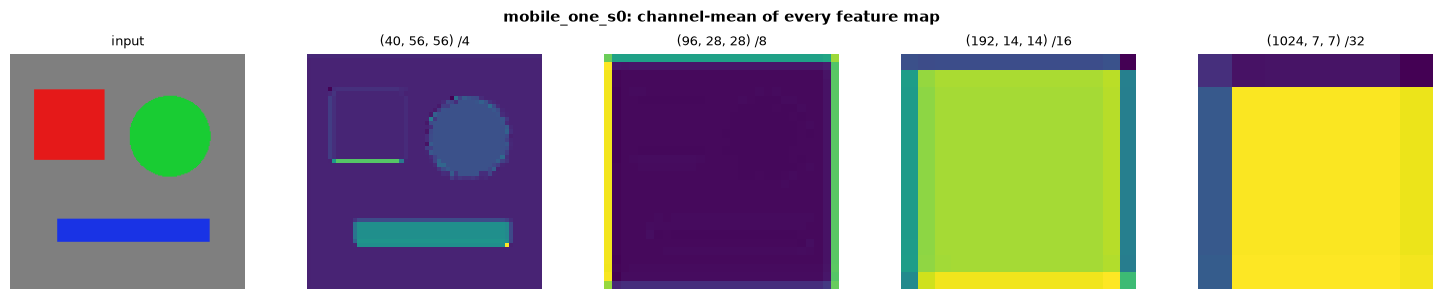

In [21]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [22]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [23]:
import sys

import torch

x = torch.randn(1, 3, 224, 224)

bb = build_vision_backbone('mobile_one_s2', img_size=224)
bb.eval()
with torch.no_grad():
    out_train = bb(x)
print(f'Before reparametrize: pooled={tuple(out_train.pooled_output.shape)}')
print(f'  params: {bb.num_parameters():,}')

# Reparametrize (fuse all branches)
def reparametrize_model(model):
    for m in model.modules():
        if isinstance(m, MobileOneBlock):
            m.reparametrize()
    return model

bb_rep = reparametrize_model(bb)
bb_rep.eval()
with torch.no_grad():
    out_inf = bb_rep(x)
print(f'After reparametrize:  pooled={tuple(out_inf.pooled_output.shape)}')
print(f'  params: {bb_rep.num_parameters():,}  (fewer — branches deleted)')

# Verify outputs are identical
max_diff = (out_train.pooled_output - out_inf.pooled_output).abs().max().item()
print(f'\nMax difference between train/inference output: {max_diff:.2e}')
print('✓ Mathematically equivalent!' if max_diff < 1e-4 else '✗ Check fusion math')

Before reparametrize: pooled=(1, 2048)
  params: 3,552,200
After reparametrize:  pooled=(1, 2048)
  params: 3,497,648  (fewer — branches deleted)

Max difference between train/inference output: 3.26e-09
✓ Mathematically equivalent!


## Model Variants

| Variant       | Width multipliers          | k  | Latency (ANE) | Top-1 (ImageNet) |
|---------------|----------------------------|----|---------------|------------------|
| mobile_one_s0 | [0.75, 1.0, 1.0, 2.0]     | 4  | 0.79 ms       | 71.4%            |
| mobile_one_s1 | [1.5,  1.5, 2.0, 2.5]     | 4  | 0.89 ms       | 75.9%            |
| mobile_one_s2 | [1.5,  2.0, 2.5, 4.0]     | 4  | 1.18 ms       | 77.4%            |
| mobile_one_s3 | [2.0,  2.5, 3.0, 4.0]     | 4  | 1.56 ms       | 78.1%            |
| mobile_one_s4 | [3.0,  3.5, 3.5, 4.0]     | 4  | 2.45 ms       | 79.4%            |

## References

1. **[Primary]** Vasu, P. K. A., Gabriel, J., Zhu, J., Tuzel, O., & Ranjan, A. (2023). **MobileOne: An Improved One millisecond Mobile Backbone**. *CVPR 2023*. https://arxiv.org/abs/2206.04040

2. Ding, X., Zhang, X., Ma, N., Han, J., Ding, G., & Sun, J. (2022). **RepVGG: Making VGG-style ConvNets Great Again**. *CVPR 2021*. — The structural re-parameterisation technique MobileOne is built on.

3. Howard, A., et al. (2019). **Searching for MobileNetV3**. *ICCV 2019*. — Prior mobile backbone that MobileOne improves upon in latency.

4. Ding, X., et al. (2022). **RepMLPNet: Hierarchical Vision MLP with Re-parameterised Mixing**. *CVPR 2022*. — Extends re-param to MLP blocks.

5. Chen, Y., et al. (2021). **Mobile-Former: Bridging MobileNet and Transformer**. *CVPR 2022*. — Hybrid mobile architecture using attention for global reasoning.